In [4]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2
from src.spectral import mean_cross_spectral
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, csd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<function matplotlib.pyplot.show(close=None, block=None)>

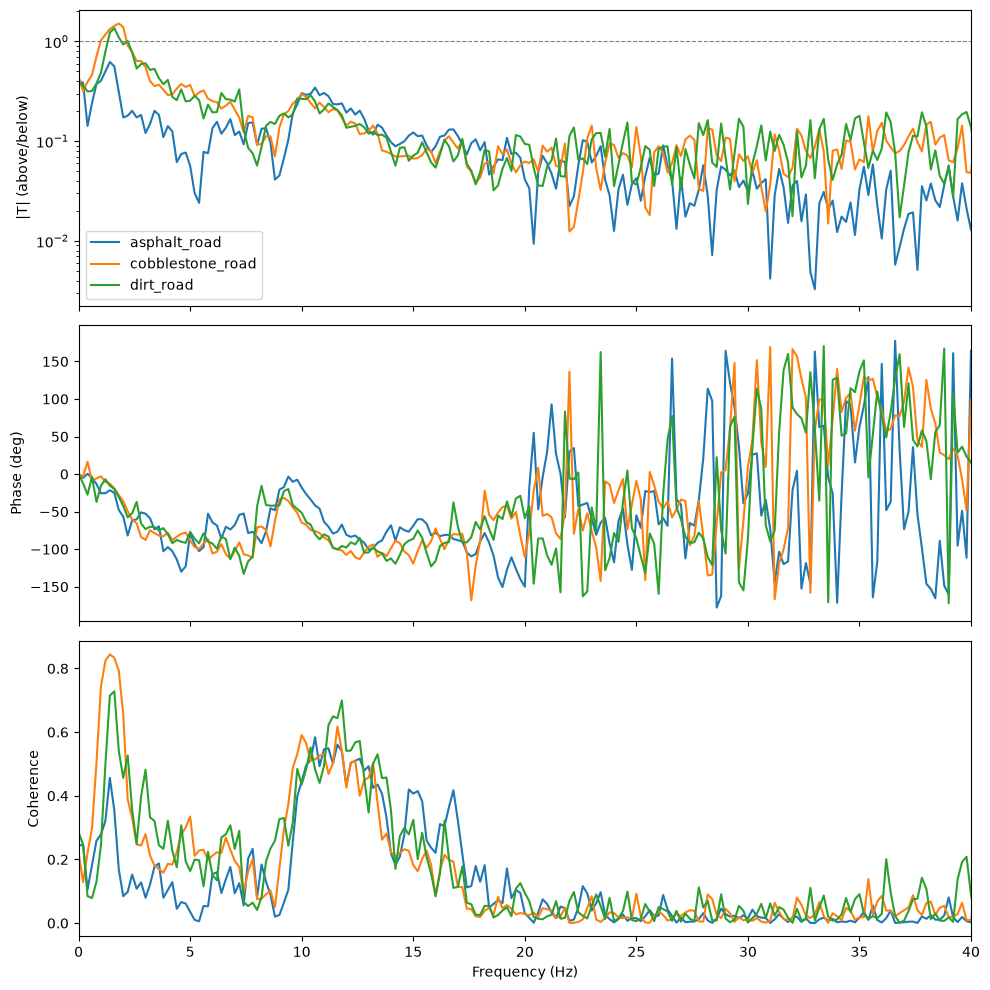

In [7]:
data={}
for side in ['left', 'right']:
    signals = pd.read_parquet(f'../data/processed/signals_PVS1_{side}.parquet')
    windows = pd.read_csv(f'../data/processed/windows_PVS1_{side}.csv', index_col='window')
    data[side] = (signals, windows)

signals, windows = data['left']
col_in, col_out = 'acc_z_below_suspension_filt', 'acc_z_above_suspension_filt'
surfaces = ['asphalt_road', 'cobblestone_road', 'dirt_road']

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex = True)
for surf in surfaces:
    ids = windows[windows['valid'] & (windows['surface'] == surf)].index
    f, Pxx, Pyy, Pxy = mean_cross_spectral(signals, ids, col_in=col_in, col_out=col_out)
    H1 = Pxy/Pxx
    coh = np.abs(Pxy)**2/(Pxx * Pyy)

    axes[0].semilogy(f, np.abs(H1), label = surf)
    axes[1].plot(f, np.degrees(np.angle(H1)))
    axes[2].plot(f, coh)

axes[0].axhline(1, c='grey', ls ='--', lw=0.8)
axes[0].set_ylabel('|T| (above/below)')
axes[1].set_ylabel('Phase (deg)')
axes[2].set_ylabel('Coherence')
axes[2].set_xlabel('Frequency (Hz)')
axes[2].set_xlim(0, 40)
axes[0].legend()
plt.tight_layout()
plt.show


In [9]:
from src.spectral import half_power_damping

rows = []
for side, (signals, windows) in data.items():
    for surf in surfaces:
        ids = windows[windows['valid'] & (windows['surface'] == surf)].index
        f, Pxx, Pyy, Pxy = mean_cross_spectral(signals, ids, col_in, col_out)
        mag = np.abs(Pxy / Pxx)
        coh = np.abs(Pxy)**2 / (Pxx * Pyy)

        fn, peak, zeta, f1, f2 = half_power_damping(f, mag, 0.5, 3)
        coh_at_peak = coh[np.argmin(np.abs(f - fn))]

        rows.append({'side': side, 'surface': surf, 'fn_hz': fn, 'T_peak': peak,
                     'f1_hz': f1, 'f2_hz': f2, 'zeta': zeta, 'coherence_at_peak': coh_at_peak})

body_mode = pd.DataFrame(rows)
display(body_mode.round(3))

,side,surface,fn_hz,T_peak,f1_hz,f2_hz,zeta,coherence_at_peak
0,left,asphalt_road,1.4,0.622,1.076,1.698,0.222,0.456
1,left,cobblestone_road,1.8,1.514,1.063,2.133,0.297,0.794
2,left,dirt_road,1.6,1.357,1.278,1.965,0.215,0.728
3,right,asphalt_road,1.4,0.378,0.785,1.824,0.371,0.283
4,right,cobblestone_road,1.6,1.438,1.076,2.072,0.311,0.815
5,right,dirt_road,1.6,0.758,1.282,1.787,0.158,0.459
